In [1]:
# Core scverse libraries
from __future__ import annotations

import anndata as ad

import scanpy as sc

In [ ]:
adata=sc.read_h5ad("GSE320040_merged.h5ad")  ## preprocessed data

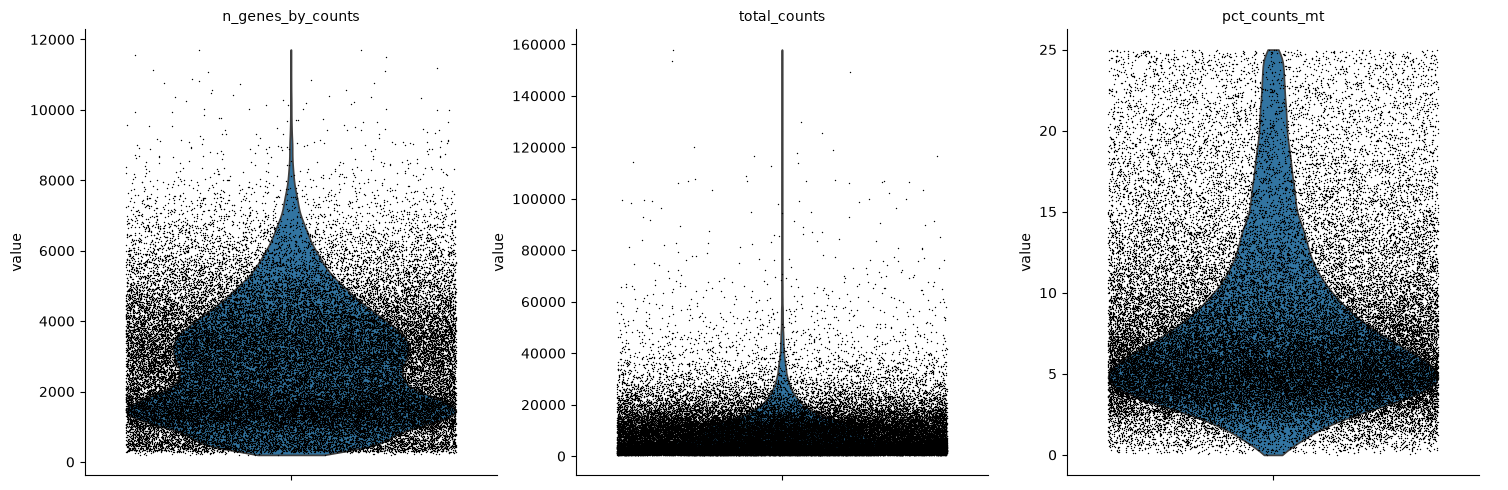

In [5]:
# mitochondrial genes, "MT-" for human, "Mt-" for mouse
adata.var["mt"] = adata.var_names.str.startswith("MT-")
# ribosomal genes
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True)

sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

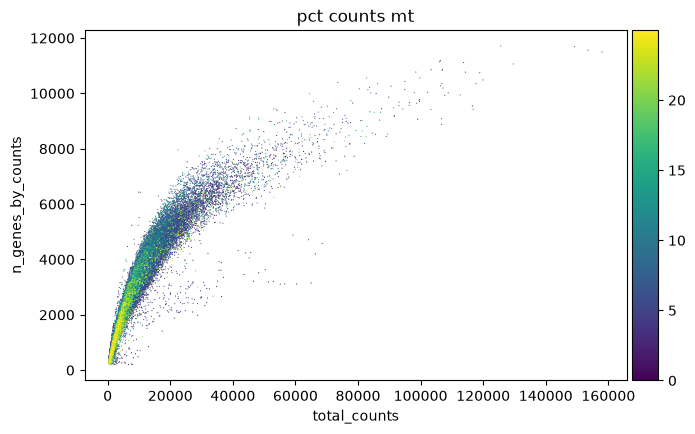

In [6]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

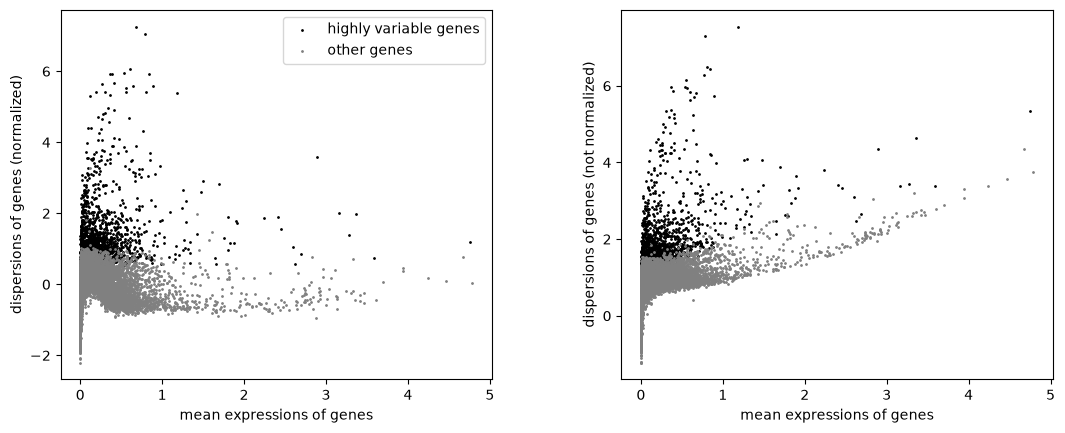

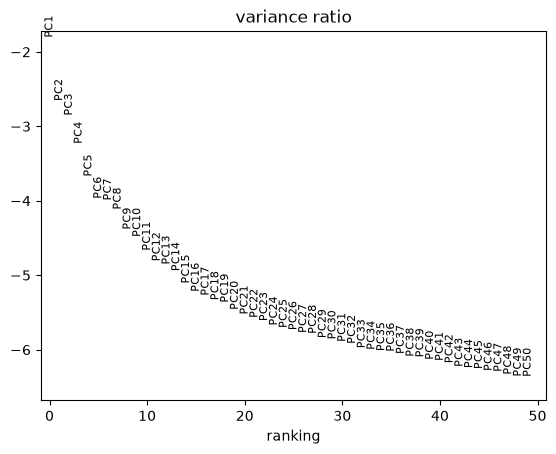

In [7]:
# Saving count data
#adata.layers["counts"] = adata.X.copy()
# Normalizing to median total counts
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="sample")
sc.pl.highly_variable_genes(adata)
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

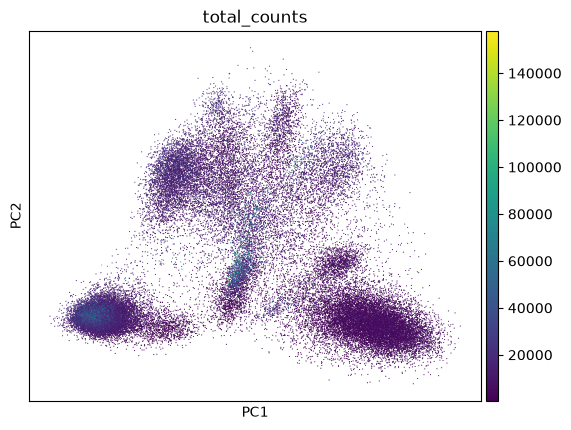

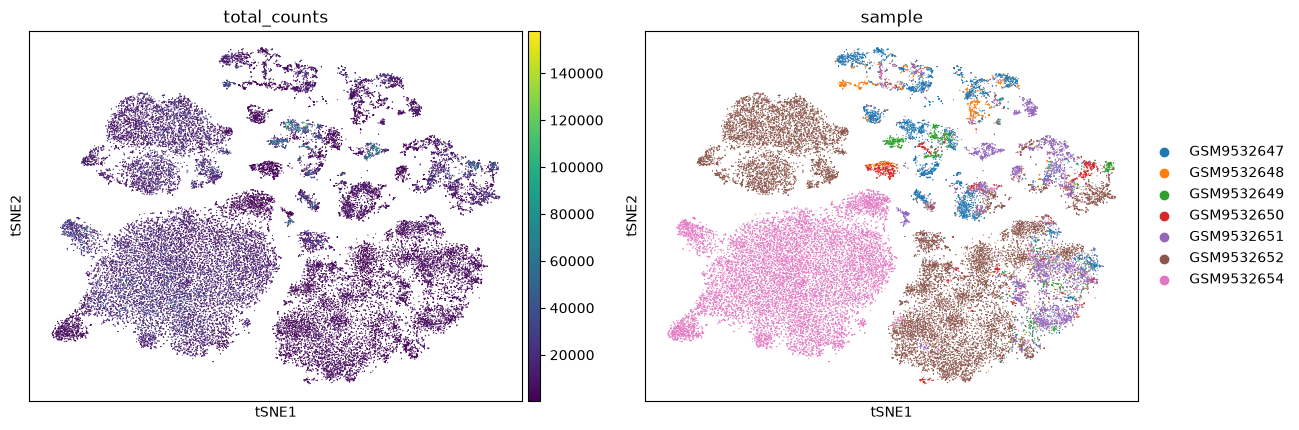

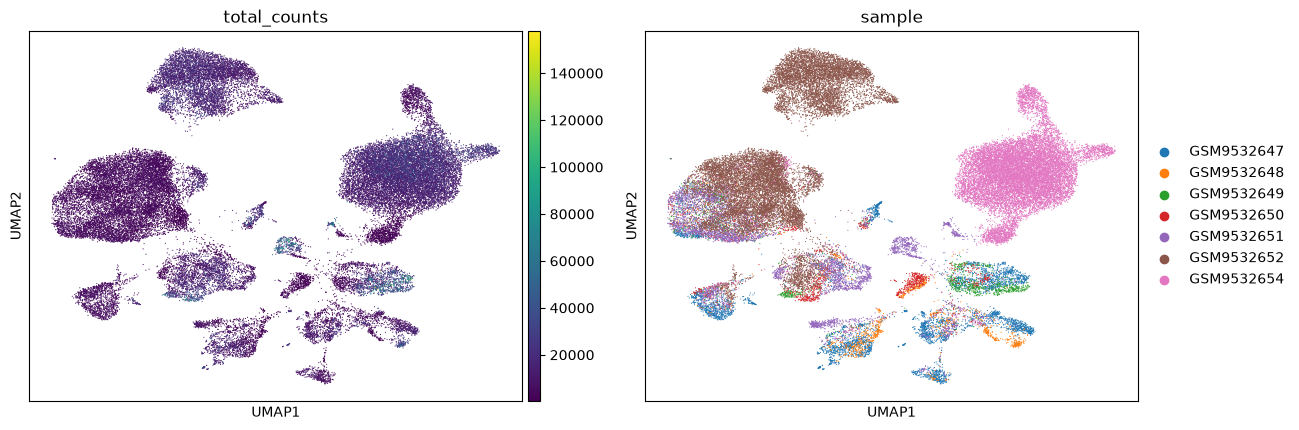

In [8]:
sc.pl.pca_scatter(adata, color="total_counts")
# t-SNE
sc.tl.tsne(adata, use_rep="X_pca")
sc.pl.tsne(adata, color=["total_counts","sample"])
# UMAP
sc.pp.neighbors(adata,n_pcs =30)
sc.tl.umap(adata)
sc.pl.umap(adata, color=["total_counts","sample"])


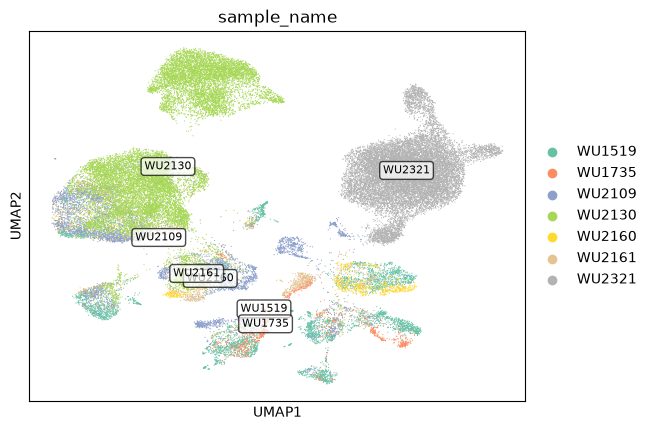

In [36]:
import numpy as np
import matplotlib.pyplot as plt

def smart_labels(adata, groupby='sample_name', fontsize=10):
    for cluster in adata.obs[groupby].unique():
        mask = adata.obs[groupby] == cluster
        x = np.median(adata.obsm['X_umap'][mask, 0])
        y = np.median(adata.obsm['X_umap'][mask, 1])
        plt.text(
            x, y, cluster,
            fontsize=fontsize,
            ha='center',
            #edgecolor='none',
            bbox=dict(facecolor='white', alpha=0.7, boxstyle='round,pad=0.3')
        )

sc.pl.umap(adata, color='sample_name', show=False)
smart_labels(adata, groupby='sample_name', fontsize=8)
plt.savefig("umap_label.pdf", dpi=300, bbox_inches="tight", facecolor="white")

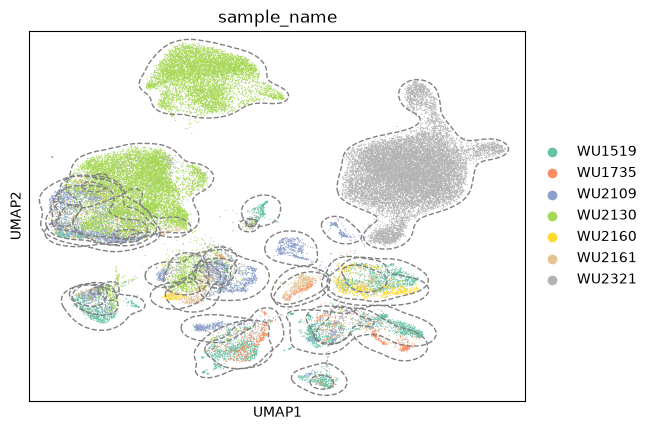

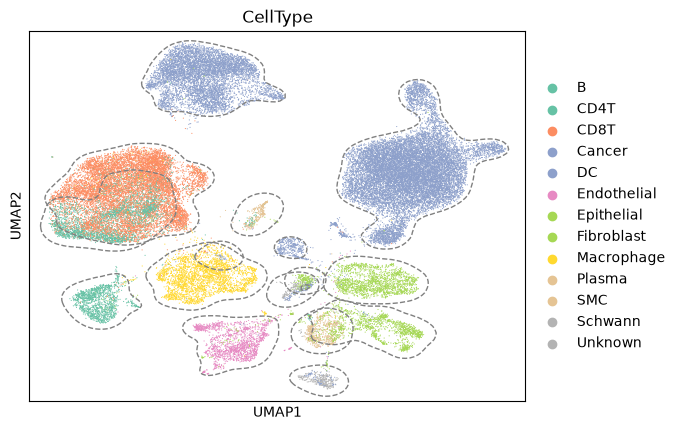

In [40]:
from sklearn.neighbors import KernelDensity
import numpy as np
import matplotlib.pyplot as plt

def add_kde_contour(adata, groupby='sample_name', bandwidth=0.5):
    fig, ax = plt.subplots()
    sc.pl.umap(adata, color=groupby, ax=ax, show=False)

    for cluster in adata.obs[groupby].unique():
        mask = adata.obs[groupby] == cluster
        coords = adata.obsm['X_umap'][mask]

        if coords.shape[0] < 2:
            continue

        x_min, x_max = coords[:, 0].min() - 1, coords[:, 0].max() + 1
        y_min, y_max = coords[:, 1].min() - 1, coords[:, 1].max() + 1

        xx, yy = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
        grid_points = np.vstack([xx.ravel(), yy.ravel()]).T

        kde = KernelDensity(bandwidth=bandwidth)
        kde.fit(coords)
        log_dens = kde.score_samples(grid_points)
        zz = np.exp(log_dens).reshape(xx.shape)

        ax.contour(
            xx, yy, zz,
            levels=[zz.max() * 0.1],
            colors='gray',
            linestyles='--',
            linewidths=1
        )
    plt.savefig("umap_kde.pdf", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()


# 默认按 celltype 画 KDE 轮廓
add_kde_contour(adata)

# 按 sample_name 画
add_kde_contour(adata, groupby='CellType')



/tmp/ipykernel_105/401034990.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


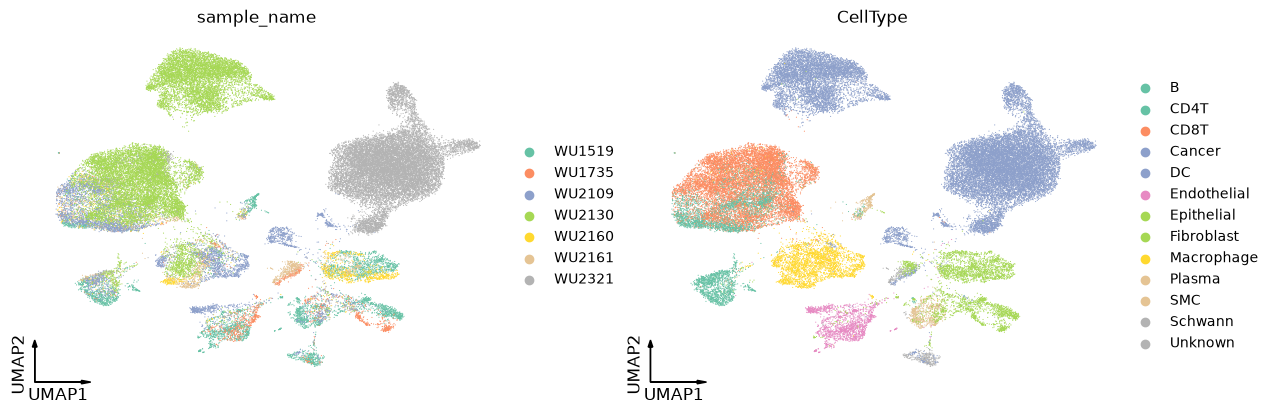

In [35]:
def scientific_axes(ax, label_size=12):
    # 获取当前坐标范围
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()

    # 计算箭头长度（数据范围的 10%）
    dx = (x_max - x_min) * 0.1
    dy = (y_max - y_min) * 0.1

    # 去掉外边框
    ax.spines[:].set_visible(False)
    # 绘制箭头
    ax.arrow(
        x_min, y_min, dx, 0,
        fc='black', ec='black',
        head_width=dy * 0.1,
        head_length=dx * 0.2
    )
    ax.arrow(
        x_min, y_min, 0, dy,
        fc='black', ec='black',
        head_width=dx * 0.1,
        head_length=dy * 0.2
    )

    # 添加标签
    ax.text(
        x_min + dx / 2, y_min - dy * 0.15,
        'UMAP1',
        ha='center', va='top', size=label_size
    )
    ax.text(
        x_min - dx * 0.15, y_min + dy / 2,
        'UMAP2',
        rotation=90, ha='right', va='center', size=label_size
    )

    # 移除默认坐标轴
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('')
    ax.set_ylabel('')


sc.pl.umap(adata, color=['sample_name', 'CellType'], show=False)

fig = plt.gcf()
for ax in fig.axes:
    scientific_axes(ax)

plt.tight_layout()

plt.savefig("umap_grid.pdf", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

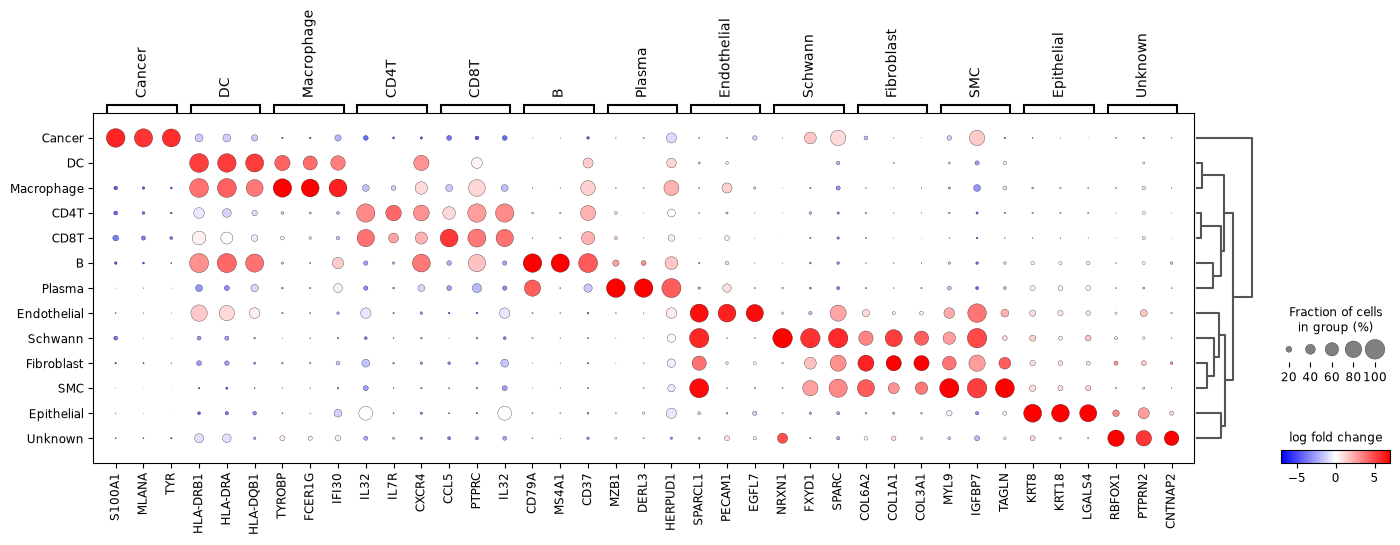

In [26]:
# Obtain cluster-specific differentially expressed genes
sc.tl.rank_genes_groups(adata, groupby="CellType", key_added='CellType_rank', method="wilcoxon")
#sc.pl.rank_genes_groups(adata, n_genes=25,key='leiden_res_1', sharey=False)

sc.pl.rank_genes_groups_dotplot(
    adata,
    #swap_axes=True,
    key='CellType_rank',
    groupby='CellType',
    n_genes=3,
    values_to_plot="logfoldchanges",
    min_logfoldchange=3,
    vmax=7,
    vmin=-7,
    cmap="bwr",
)

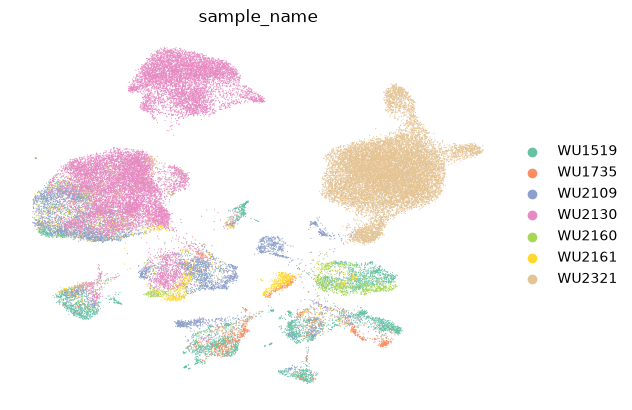

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 
palette = sns.color_palette("Set2",7)
# 
palette = sns.color_palette("tab10", 12)

sc.pl.umap(
    adata,
    color="sample_name",
    palette=sns.color_palette("Set2", 7),
    frameon=False,
   # legend_loc="on data",
    legend_fontoutline=2,
)

In [ ]:
## custom distinguishable color pallette

In [ ]:
# palette_library.py

PALETTES = {
    # ---------- 高对比离散配色 ----------
    "high_contrast_8": [
        "#E41A1C",  # 
        "#377EB8",  # 
        "#4DAF4A",  # 
        "#984EA3",  # 
        "#FF7F00",  # 
        "#A65628",  # 
        "#F781BF",  # 
        "#999999",  # 
    ],
    "high_contrast_12": [
        "#E41A1C",
        "#377EB8",
        "#4DAF4A",
        "#984EA3",
        "#FF7F00",
        "#A65628",
        "#F781BF",
        "#999999",
        "#66C2A5",
        "#FC8D62",
        "#8DA0CB",
        "#FFD92F",
    ],
    "high_contrast_16": [
        "#E41A1C",
        "#377EB8",
        "#4DAF4A",
        "#984EA3",
        "#FF7F00",
        "#A65628",
        "#F781BF",
        "#999999",
        "#66C2A5",
        "#FC8D62",
        "#8DA0CB",
        "#FFD92F",
        "#1B9E77",
        "#D95F02",
        "#7570B3",
        "#E7298A",
    ],

    # ---------- 样本 / 组别常用 ----------
    "sample_6": [
        "#E41A1C",
        "#377EB8",
        "#4DAF4A",
        "#FF7F00",
        "#984EA3",
        "#A65628",
    ],
    "sample_10": [
        "#E41A1C",
        "#377EB8",
        "#4DAF4A",
        "#FF7F00",
        "#984EA3",
        "#A65628",
        "#F781BF",
        "#66C2A5",
        "#FC8D62",
        "#8DA0CB",
    ],

    # ---------- 细胞类型常用 ----------
    "celltype_8": [
        "#E41A1C",
        "#377EB8",
        "#4DAF4A",
        "#984EA3",
        "#FF7F00",
        "#A65628",
        "#1B9E77",
        "#D95F02",
    ],
    "celltype_12": [
        "#E41A1C",
        "#377EB8",
        "#4DAF4A",
        "#984EA3",
        "#FF7F00",
        "#A65628",
        "#F781BF",
        "#999999",
        "#66C2A5",
        "#FC8D62",
        "#8DA0CB",
        "#FFD92F",
    ],

    # ---------- 疾病 / 对照 / 处理 ----------
    "condition_4": [
        "#E41A1C",
        "#377EB8",
        "#4DAF4A",
        "#FF7F00",
    ],
    "condition_6": [
        "#E41A1C",
        "#377EB8",
        "#4DAF4A",
        "#FF7F00",
        "#984EA3",
        "#A65628",
    ],
}


def get_palette(name, n=None):
    """
    返回一个适合 scanpy palette 使用的颜色列表。

    Parameters
    ----------
    name : str
        配色名称，例如 "high_contrast_12"
    n : int, optional
        只取前 n 个颜色。
    """
    colors = PALETTES[name]
    if n is not None:
        return colors[:n]
    return colors


def auto_palette(adata, groupby, preset="celltype"):
    """
    根据 obs 中的类别数，自动返回高对比配色。
    """
    n = adata.obs[groupby].nunique()
    if preset == "sample":
        key = "sample_10" if n <= 10 else "high_contrast_16"
    elif preset == "condition":
        key = "condition_6" if n <= 6 else "high_contrast_12"
    else:
        key = "celltype_12" if n <= 12 else "high_contrast_16"
    return get_palette(key, n)

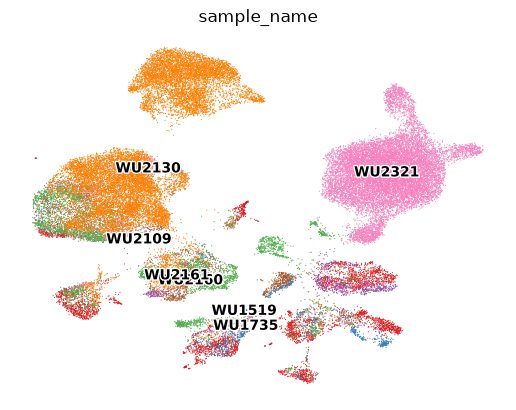

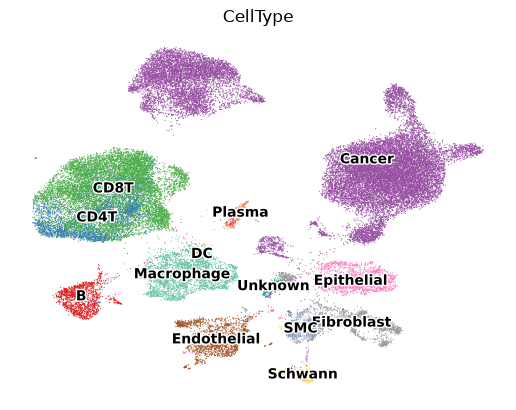

In [48]:
#from palette_library import get_palette, auto_palette

# 手动指定
sc.pl.umap(
    adata,
    color="sample_name",
    palette=get_palette("sample_10"),
    frameon=False,
    legend_loc="on data",
    legend_fontoutline=2,
)

# 自动按类别数选色
sc.pl.umap(
    adata,
    color="CellType",
    palette=auto_palette(adata, "CellType", preset="celltype"),
    frameon=False,
    legend_loc="on data",
    legend_fontoutline=2,
)